# When two observers can read the same existing record

A fixed source contains two readable copies of a uniform classical bit and two blank carriers. This notebook changes only how two observers receive distinct carriers. Each observer receives every carrier equally often in both protocols. Does that determine whether **both** observers answer correctly in the same trial?

It does not. We optimize all $64\times64=4096$ deterministic local decoder pairs, keep failed trials, and then change the communication rule. Random local strategies and shared randomness cannot improve a linear score beyond the best deterministic pair.

This is a statement about acquiring existing classical records. It neither changes the source's intrinsic redundancy nor establishes objectivity for arbitrary quantum states. Classical copying and quantum diary recovery are different tasks.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, str(Path.cwd() / 'code'))
from receiver_extensions.paths import DATA, verify_inputs, save_result
manifest = verify_inputs()
print('Packaged input hashes verified:', ', '.join(manifest))


Packaged input hashes verified: frozen_inputs.npz, scalar_flux_grid_384.npz


In [2]:
from receiver_extensions.record_access import calculate, PAIRS, mask_law, local_decoder_optimum
records = calculate()
rows = []
for name,r in records['protocols'].items():
    rows.append(dict(protocol=name, masks=str(r['ordered_pairs_one_based']), q=r['probability_both_readable'],
                     individual_correct=r['optimal_individual_correctness'][0],
                     local_information=r['local_mutual_information_bits'][0],
                     both_correct_no_communication=r['optimal_both_correct_no_communication'],
                     both_correct_with_communication=r['optimal_both_correct_communication_allowed'],
                     pooled_information=r['pooled_mutual_information_bits']))
display(pd.DataFrame(rows).set_index('protocol'))
print('Exact uniform-fragment information curve:',records['uniform_fragment_source_information_plot_bits'])
print('Decoder enumeration:',records['decoder_enumeration'])


,masks,q,individual_correct,local_information,both_correct_no_communication,both_correct_with_communication,pooled_information
protocol,,,,,,,
A,"[[np.int64(1), np.int64(2)], [np.int64(2), np....",0.5,0.75,0.5,0.75,0.75,0.5
B,"[[np.int64(1), np.int64(3)], [np.int64(2), np....",0.0,0.75,0.5,0.50,1.00,1.0


Exact uniform-fragment information curve: ['0', '1/2', '5/6', '1', '1']
Decoder enumeration: {'maps_per_observer': 64, 'map_pairs': 4096, 'mixture_cases_checked': 11}


Protocol A supplies two readable records together, or two blanks together. Protocol B always supplies one readable record and one blank. Both observers individually score $3/4$ and acquire $1/2$ bit on average. Without communication, A wins: $3/4$ against $1/2$. Allowing the observers to share their records reverses the ranking: B reaches 1 while A remains at $3/4$.

The source's uniform-fragment curve is fixed at $(0,1/2,5/6,1,1)$ bits. The actual pooled information is **not** matched: it is $1-q$ bits. A comparison that equated these two kinds of average would erase the relevant distinction.

## The missing statistic and its calibration certificate

Let $q$ be the probability that both observers receive readable carriers. With uniform local carrier marginals, linear programming gives $0\le q\le1/2$. The optimized joint scores are

$$P_{\mathrm{local}}=\tfrac12+\tfrac q2,\qquad
P_{\mathrm{communicating}}=1-\tfrac q2.$$

The existing calibration matrix has rank 7. Adding the joint event raises it to 8 and places the no-communication joint score in its row space. The following exact rational elimination independently checks those ranks; numerical optimization checks the attainable endpoints.


In [3]:
from fractions import Fraction

def rational_rank(matrix):
    a = [[Fraction(int(v)) for v in row] for row in matrix]
    rank = 0
    for col in range(len(a[0])):
        pivot = next((i for i in range(rank,len(a)) if a[i][col]),None)
        if pivot is None: continue
        a[rank],a[pivot] = a[pivot],a[rank]
        value = a[rank][col]
        a[rank] = [v/value for v in a[rank]]
        for i in range(len(a)):
            if i!=rank:
                value=a[i][col]; a[i]=[v-value*u for v,u in zip(a[i],a[rank])]
        rank += 1
    return rank

matrix = [np.ones(12,dtype=int)]
for observer in [0,1]:
    for site in range(4): matrix.append([int(pair[observer]==site) for pair in PAIRS])
both = [int(a<2 and b<2) for a,b in PAIRS]
exact_ranks = [rational_rank(matrix),rational_rank(matrix+[both])]
assert exact_ranks == [7,8]
print('Exact rational ranks:',exact_ranks)
print('LP interval for q:',records['compatible_probability_both_readable_interval'])
print('Joint correctness interval:',records['compatible_local_joint_correctness_interval'])


Exact rational ranks: [7, 8]
LP interval for q: [0.0, 0.5]
Joint correctness interval: [0.5, 0.75]


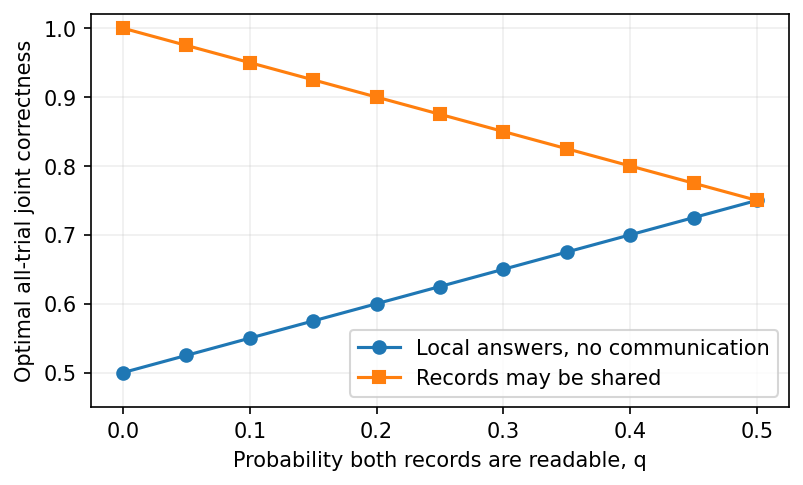

In [4]:
A = mask_law([(0,1),(1,0),(2,3),(3,2)])
B = mask_law([(0,2),(2,0),(1,3),(3,1)])
qs, local, communicating = [], [], []
for t in np.linspace(0,1,11):
    w = t*A+(1-t)*B
    q = float(np.asarray(both)@w)
    score,_ = local_decoder_optimum(w)
    assert abs(score-(.5+.5*q))<1e-14
    qs.append(q); local.append(score); communicating.append(1-.5*q)
fig,ax=plt.subplots(figsize=(6,3.4))
ax.plot(qs,local,'o-',label='Local answers, no communication')
ax.plot(qs,communicating,'s-',label='Records may be shared')
ax.set(xlabel='Probability both records are readable, q',ylabel='Optimal all-trial joint correctness',ylim=(.45,1.02))
ax.legend();ax.grid(alpha=.2);plt.show()


The intersection shows that a collection protocol cannot be ranked independently of the allowed interface. The two endpoints are the matched-marginal protocols above; the intermediate points are their mixtures, each checked by decoder enumeration.

## Controls that delimit the claim

The masks must be independent of the source bit. A supplied counterexample keeps local carrier identities uniform but lets the joint mask itself reveal the bit. The notebook verifies that this public mask carries one full bit. A second, separate control compares a coherent repetition encoding with its dephased version: perfect classical record readability survives, while decoded Bell fidelity falls from 1 to 1/2. The control is not a claim that their full quantum mutual information is equal.


In [5]:
print('Source-dependent public-mask information:',records['source_independence_counterexample_public_mask_information_bits'],'bit')
display(pd.DataFrame([records['coherence_control']]))
records['exact_rational_calibration_ranks'] = exact_ranks
print('Computed evidence saved:',save_result('joint_record_access.json',records))


Source-dependent public-mask information: 1.0 bit


,full_register_Bell_fidelity_before_after_dephasing,single_record_reference_state_maximum_difference,pointer_readout_accuracy_before_after,scope
0,"[0.9999999999999997, 0.49999999999999983]",0.0,"[1.0, 1.0]",Distinct coherent/dephased sources; their full...


Computed evidence saved: outputs/runs/integration_process_20261105/extensions/joint_record_access.json


The probability interval and linear sufficiency argument use established coupling and linear-identifiability methods. Fragment averaging, redundancy, and operational consensus have prior distinctions in quantum Darwinism; see Chisholm *et al.*, **Quantum 7, 1074 (2023)**. The contribution of this construction is the specified observer task, a calibrated joint statistic, and the communication-dependent reversal for a fixed source. No firstness claim about redundancy or fragment averages follows.
